In [1]:
import torch

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

assert torch.cuda.is_available(), (
    "No GPU is active. Open Runtime → Change runtime type and select GPU."
)

print("GPU:", torch.cuda.get_device_name(0))
print("VRAM (GB):", round(torch.cuda.get_device_properties(0).total_memory / 1e9, 1))

PyTorch: 2.11.0+cu130
CUDA available: True
GPU: NVIDIA RTX PRO 6000 Blackwell Server Edition
VRAM (GB): 102.0


In [2]:
from google.colab import drive
from pathlib import Path

drive.mount("/content/drive")

PROJECT_DIR = Path("/content/drive/MyDrive/nightthoughts-incident-triage")
DATA_DIR = PROJECT_DIR / "data"
RESULTS_DIR = PROJECT_DIR / "results"
ADAPTER_DIR = PROJECT_DIR / "adapter"

for directory in [PROJECT_DIR, DATA_DIR, RESULTS_DIR, ADAPTER_DIR]:
    directory.mkdir(parents=True, exist_ok=True)

print("Project folder:", PROJECT_DIR)

Mounted at /content/drive
Project folder: /content/drive/MyDrive/nightthoughts-incident-triage


In [3]:
!pip install -q unsloth

In [4]:
from unsloth import FastLanguageModel

print("Unsloth imported successfully.")


🦥 Unsloth: Will patch your computer to enable 2x faster free finetuning.
Unsloth: xformers is installed but cannot load with torch 2.11.0+cu130 (it was built for 2.10.0+cu128), so PyTorch attention is used instead.
To install a matching xformers, run `unsloth install-kernels xformers`, or `pip uninstall xformers` to hide this. UNSLOTH_ENABLE_LOGGING=1 shows the full error.
🦥 Unsloth Zoo will now patch everything to make training faster!
Unsloth imported successfully.


In [6]:
import json
import random
from collections import Counter, defaultdict

SCENARIOS = [
    # Training scenarios
    dict(id="db_pool_payments", split="train", service="payments-api", severity="sev2", category="database_capacity", next_action="inspect_database_connections", summary="Database connection-pool exhaustion is causing checkout timeouts", alert="Payments API checkout timeouts reached {pct}% after the database connection pool hit its limit. Retries are increasing and {n}% of requests are queued."),
    dict(id="db_connections_inventory", split="train", service="inventory", severity="sev2", category="database_capacity", next_action="inspect_database_connections", summary="Inventory workers cannot obtain enough database connections", alert="Inventory workers have exhausted their PostgreSQL connections. Stock updates are waiting for a free connection and the backlog has reached {n} jobs."),
    dict(id="db_slow_queries_search", split="train", service="search", severity="sev3", category="database_capacity", next_action="inspect_database_connections", summary="Search latency is rising under expensive database queries", alert="Search p95 latency increased to {n} ms. The primary database shows concurrent expensive queries and CPU saturation, but the last deployment was three days ago."),
    dict(id="deploy_checkout_timeouts", split="train", service="payments-api", severity="sev1", category="deployment_regression", next_action="inspect_recent_deployment", summary="Checkout failures began immediately after a payments deployment", alert="At 02:{minutes}, version 2026.10.{n} was deployed to payments-api. Within two minutes, checkout errors rose to {pct}% while the previous version remains healthy."),
    dict(id="deploy_search_errors", split="train", service="search", severity="sev2", category="deployment_regression", next_action="inspect_recent_deployment", summary="Search errors started with the latest release", alert="The search service began returning 500 responses immediately after release {n}. Error rate is {pct}%; the canary did not show this behavior."),
    dict(id="deploy_auth_config", split="train", service="authentication", severity="sev2", category="deployment_regression", next_action="inspect_recent_deployment", summary="Login failures followed an authentication configuration release", alert="A configuration deployment to authentication completed {minutes} minutes ago. Since then, valid logins have failed across all regions; authentication CPU and network metrics are normal."),
    dict(id="auth_token_clock", split="train", service="authentication", severity="sev3", category="authentication", next_action="inspect_auth_configuration", summary="Token validation is failing because of clock or timestamp checks", alert="Authentication rejects otherwise valid JWTs with not-before and expiration errors. One node reports a clock offset of {n} seconds; traffic and recent deployments are unchanged."),
    dict(id="auth_sso_loop", split="train", service="authentication", severity="sev2", category="authentication", next_action="inspect_auth_configuration", summary="Users are trapped in an SSO redirect loop", alert="Users cannot complete SSO login and loop between the identity provider and authentication. The callback reports a state or nonce mismatch for {pct}% of attempts."),
    dict(id="auth_permission_cache", split="train", service="authentication", severity="sev3", category="authentication", next_action="inspect_auth_configuration", summary="Authorization changes are not taking effect", alert="Revoked user permissions remain valid for up to {minutes} minutes. Authentication logs show stale role claims served from the authorization cache."),
    dict(id="network_dns_inventory", split="train", service="inventory", severity="sev2", category="network", next_action="inspect_network_path", summary="Inventory dependencies are unreachable because DNS resolution fails", alert="Inventory cannot resolve its database hostname. DNS lookups time out in two availability zones, while direct connections to the previously resolved address still work."),
    dict(id="network_packet_loss_payments", split="train", service="payments-api", severity="sev1", category="network", next_action="inspect_network_path", summary="Packet loss is disrupting payments traffic", alert="Payments-api is timing out across multiple backends. The network path shows {pct}% packet loss and retransmissions; application error logs have not changed."),
    dict(id="network_lb_search", split="train", service="search", severity="sev2", category="network", next_action="inspect_network_path", summary="One load-balancer route is dropping search requests", alert="Search requests fail only through one load-balancer route. Backend health checks pass locally, but the affected route resets {pct}% of connections."),
    dict(id="unknown_queue_notifications", split="train", service="unknown", severity="sev3", category="unknown", next_action="request_more_context", summary="The alert does not isolate a cause for delayed asynchronous work", alert="Asynchronous work is delayed and a queue depth graph is rising. Dashboards disagree about the owning service, and no dependency, release, or error evidence is available."),
    dict(id="unknown_disk_inventory", split="train", service="unknown", severity="sev3", category="unknown", next_action="request_more_context", summary="A host disk warning lacks enough evidence for incident classification", alert="A host is above {pct}% disk usage. The owning application and customer impact are unclear, and there is no evidence yet of database, deployment, authentication, or network failure."),
    dict(id="unknown_third_party", split="train", service="unknown", severity="sev4", category="unknown", next_action="request_more_context", summary="A vendor notice has no established service impact", alert="A third-party provider reports degradation in one region. Our monitoring shows no confirmed impact, affected service, or relevant internal errors."),

    # Validation scenarios: none appear in training
    dict(id="db_replication_lag", split="validation", service="inventory", severity="sev2", category="database_capacity", next_action="inspect_database_connections", summary="Database replication lag is overloading the inventory primary", alert="Inventory reads are being redirected to the primary because replica lag exceeds {n} seconds. Primary connections and query latency are now climbing."),
    dict(id="deploy_notification_retry", split="validation", service="notifications", severity="sev3", category="deployment_regression", next_action="inspect_recent_deployment", summary="A notification release introduced excessive retries", alert="Notification retry volume tripled immediately after worker release {n}. Delivery latency is increasing, while the previous worker version processes the same events normally."),
    dict(id="auth_expired_certificate", split="validation", service="authentication", severity="sev1", category="authentication", next_action="inspect_auth_configuration", summary="An expired signing certificate is blocking authentication", alert="All new SSO assertions fail signature validation. The authentication signing certificate expired {minutes} minutes ago; infrastructure connectivity is healthy."),
    dict(id="network_gateway_timeouts", split="validation", service="notifications", severity="sev2", category="network", next_action="inspect_network_path", summary="Gateway timeouts are interrupting notification delivery", alert="Notifications cannot reach the external gateway. TCP connections time out after {n} seconds in every region, while internal service-to-service calls remain healthy."),
    dict(id="unknown_metrics_gap", split="validation", service="unknown", severity="sev4", category="unknown", next_action="request_more_context", summary="Missing telemetry prevents a supported classification", alert="A dashboard panel has been blank for {minutes} minutes. The affected service, user impact, and underlying error are unknown."),

    # Test scenarios: unseen during both training and model selection
    dict(id="db_deadlock_payments", split="test", service="payments-api", severity="sev2", category="database_capacity", next_action="inspect_database_connections", summary="Database deadlocks are reducing payments capacity", alert="Payments-api database deadlocks increased to {n} per minute. Transactions roll back and connection wait time is rising, although no release occurred today."),
    dict(id="deploy_migration_errors", split="test", service="payments-api", severity="sev1", category="deployment_regression", next_action="inspect_recent_deployment", summary="A schema migration release broke payment writes", alert="Payment writes fail with an unknown-column error immediately after migration release {n}. Reads on the old path are healthy and failures correlate exactly with rollout progress."),
    dict(id="auth_key_rotation", split="test", service="authentication", severity="sev2", category="authentication", next_action="inspect_auth_configuration", summary="A signing-key rotation broke token verification", alert="Token verification began failing after last night's signing-key rotation. Old and new keys are being served inconsistently across authentication nodes."),
    dict(id="network_ipv6_route", split="test", service="search", severity="sev3", category="network", next_action="inspect_network_path", summary="A broken IPv6 route is delaying search dependencies", alert="Search dependency calls over IPv6 time out, forcing connection fallback after {n} seconds. IPv4 requests to the same hosts complete normally."),
    dict(id="unknown_worker_saturation", split="test", service="unknown", severity="sev3", category="unknown", next_action="request_more_context", summary="Generic worker saturation has no isolated root cause", alert="Several workers report high CPU and slower processing. There is no confirmed owning service, recent release, dependency failure, or authentication evidence."),
]

SERVICES = ["payments-api", "authentication", "search", "inventory", "notifications", "unknown"]
SEVERITIES = ["sev1", "sev2", "sev3", "sev4"]
CATEGORIES = ["database_capacity", "deployment_regression", "authentication", "network", "unknown"]
ACTIONS = [
    "inspect_database_connections",
    "inspect_recent_deployment",
    "inspect_auth_configuration",
    "inspect_network_path",
    "request_more_context",
]

print("Scenarios by split:", Counter(s["split"] for s in SCENARIOS))


Scenarios by split: Counter({'train': 15, 'validation': 5, 'test': 5})


In [7]:
PREFIXES = ["", "[alertmanager] ", "PRODUCTION: ", "On-call note: ", "Incident update: "]
SUFFIXES = [
    "",
    " The runbook has not been updated.",
    " No remediation has been attempted.",
    " Customer support is monitoring the situation.",
    " Keep this as an investigation-only alert.",
]

TARGET_FIELDS = ["service", "severity", "category", "summary", "next_action", "escalate"]

def make_record(scenario, sequence, rng):
    values = {
        "n": rng.randint(4, 900),
        "pct": rng.randint(8, 65),
        "minutes": rng.randint(2, 55),
    }

    alert = scenario["alert"].format(**values)
    alert = rng.choice(PREFIXES) + alert + rng.choice(SUFFIXES)
    alert += f" Incident reference: INC-{sequence:05d}."

    target = {key: scenario[key] for key in TARGET_FIELDS[:-1]}
    target["escalate"] = scenario["severity"] in {"sev1", "sev2"}

    return {
        "scenario_id": scenario["id"],
        "split": scenario["split"],
        "alert": alert,
        "target": json.dumps(target, ensure_ascii=False),
    }

rng = random.Random(3407)
records = []
examples_per_split = {"train": 100, "validation": 80, "test": 80}

sequence = 0
for scenario in SCENARIOS:
    for _ in range(examples_per_split[scenario["split"]]):
        sequence += 1
        records.append(make_record(scenario, sequence, rng))

train_records = [r for r in records if r["split"] == "train"]
validation_records = [r for r in records if r["split"] == "validation"]
test_records = [r for r in records if r["split"] == "test"]

print("Examples:", {split: len(items) for split, items in {
    "train": train_records,
    "validation": validation_records,
    "test": test_records,
}.items()})
print("Unique alerts:", len({r["alert"] for r in records}))
print("First target:", test_records[0]["target"])


Examples: {'train': 1500, 'validation': 400, 'test': 400}
Unique alerts: 2300
First target: {"service": "payments-api", "severity": "sev2", "category": "database_capacity", "summary": "Database deadlocks are reducing payments capacity", "next_action": "inspect_database_connections", "escalate": true}


In [8]:
scenario_sets = {
    split: {r["scenario_id"] for r in items}
    for split, items in {
        "train": train_records,
        "validation": validation_records,
        "test": test_records,
    }.items()
}

assert not scenario_sets["train"] & scenario_sets["validation"]
assert not scenario_sets["train"] & scenario_sets["test"]
assert not scenario_sets["validation"] & scenario_sets["test"]
assert len({r["alert"] for r in records}) == len(records)

for split, items in {
    "train": train_records,
    "validation": validation_records,
    "test": test_records,
}.items():
    category_counts = Counter(json.loads(r["target"])["category"] for r in items)
    print(split, "scenario IDs:", sorted(scenario_sets[split]))
    print(split, "categories:", dict(category_counts))


train scenario IDs: ['auth_permission_cache', 'auth_sso_loop', 'auth_token_clock', 'db_connections_inventory', 'db_pool_payments', 'db_slow_queries_search', 'deploy_auth_config', 'deploy_checkout_timeouts', 'deploy_search_errors', 'network_dns_inventory', 'network_lb_search', 'network_packet_loss_payments', 'unknown_disk_inventory', 'unknown_queue_notifications', 'unknown_third_party']
train categories: {'database_capacity': 300, 'deployment_regression': 300, 'authentication': 300, 'network': 300, 'unknown': 300}
validation scenario IDs: ['auth_expired_certificate', 'db_replication_lag', 'deploy_notification_retry', 'network_gateway_timeouts', 'unknown_metrics_gap']
validation categories: {'database_capacity': 80, 'deployment_regression': 80, 'authentication': 80, 'network': 80, 'unknown': 80}
test scenario IDs: ['auth_key_rotation', 'db_deadlock_payments', 'deploy_migration_errors', 'network_ipv6_route', 'unknown_worker_saturation']
test categories: {'database_capacity': 80, 'deployme

In [9]:
for record in test_records[:2]:
    print("ALERT:", record["alert"])
    print("TARGET:", record["target"])
    print()

for split, items in {
    "train": train_records,
    "validation": validation_records,
    "test": test_records,
}.items():
    path = DATA_DIR / f"{split}.jsonl"
    with path.open("w", encoding="utf-8") as handle:
        for record in items:
            handle.write(json.dumps(record, ensure_ascii=False) + "\n")
    print("Saved", len(items), "examples to", path)


ALERT: Incident update: Payments-api database deadlocks increased to 153 per minute. Transactions roll back and connection wait time is rising, although no release occurred today. Incident reference: INC-01901.
TARGET: {"service": "payments-api", "severity": "sev2", "category": "database_capacity", "summary": "Database deadlocks are reducing payments capacity", "next_action": "inspect_database_connections", "escalate": true}

ALERT: [alertmanager] Payments-api database deadlocks increased to 549 per minute. Transactions roll back and connection wait time is rising, although no release occurred today. No remediation has been attempted. Incident reference: INC-01902.
TARGET: {"service": "payments-api", "severity": "sev2", "category": "database_capacity", "summary": "Database deadlocks are reducing payments capacity", "next_action": "inspect_database_connections", "escalate": true}

Saved 1500 examples to /content/drive/MyDrive/nightthoughts-incident-triage/data/train.jsonl
Saved 400 exam

In [10]:
SYSTEM_PROMPT = f"""You convert incident alerts into strict JSON objects.
Return one JSON object and nothing else. Do not use Markdown fences.
Use exactly these keys: service, severity, category, summary, next_action, escalate.
Allowed service values: {json.dumps(SERVICES)}.
Allowed severity values: {json.dumps(SEVERITIES)}.
Allowed category values: {json.dumps(CATEGORIES)}.
Allowed next_action values: {json.dumps(ACTIONS)}.
summary must be a short non-empty string. escalate must be a JSON boolean.
Escalate sev1 and sev2. Do not escalate sev3 and sev4.
If the evidence is insufficient, use category unknown, service unknown,
and next_action request_more_context rather than inventing a cause."""

def prompt_messages(alert):
    return [
        {"role": "system", "content": SYSTEM_PROMPT},
        {"role": "user", "content": "Classify this incident alert.\n\n" + alert},
    ]

def training_messages(record):
    target = json.dumps(json.loads(record["target"]), ensure_ascii=False, separators=(",", ":"))
    return prompt_messages(record["alert"]) + [
        {"role": "assistant", "content": target}
    ]

print(SYSTEM_PROMPT)
print(training_messages(train_records[0]))


You convert incident alerts into strict JSON objects.
Return one JSON object and nothing else. Do not use Markdown fences.
Use exactly these keys: service, severity, category, summary, next_action, escalate.
Allowed service values: ["payments-api", "authentication", "search", "inventory", "notifications", "unknown"].
Allowed severity values: ["sev1", "sev2", "sev3", "sev4"].
Allowed category values: ["database_capacity", "deployment_regression", "authentication", "network", "unknown"].
Allowed next_action values: ["inspect_database_connections", "inspect_recent_deployment", "inspect_auth_configuration", "inspect_network_path", "request_more_context"].
summary must be a short non-empty string. escalate must be a JSON boolean.
Escalate sev1 and sev2. Do not escalate sev3 and sev4.
If the evidence is insufficient, use category unknown, service unknown,
and next_action request_more_context rather than inventing a cause.
[{'role': 'system', 'content': 'You convert incident alerts into stric

In [11]:
MAX_SEQ_LENGTH = 1024
BASE_MODEL = "unsloth/Qwen2.5-1.5B-Instruct"

model, tokenizer = FastLanguageModel.from_pretrained(
    model_name=BASE_MODEL,
    max_seq_length=MAX_SEQ_LENGTH,
    dtype=None,
    load_in_4bit=True,
)

print("Loaded:", BASE_MODEL)
print("Tokenizer chat template available:", tokenizer.chat_template is not None)


==((====))==  Unsloth 2026.10.10: Fast Qwen2 patching. Transformers: 5.17.0.
   \\   /|    NVIDIA RTX PRO 6000 Blackwell Server Edition. Num GPUs = 1. Max memory: 94.971 GB. Platform: Linux.
O^O/ \_/ \    Torch: 2.11.0+cu130. CUDA: 12.0. CUDA Toolkit: 13.0. Triton: 3.6.0
\        /    Bfloat16 = TRUE. FA [Xformers = None. FA2 = False]
 "-____-"     Free license: http://github.com/unslothai/unsloth
Unsloth: Fast downloading is enabled - ignore downloading bars which are red colored!


Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

Loaded: unsloth/Qwen2.5-1.5B-Instruct
Tokenizer chat template available: True


In [12]:
from datasets import Dataset

def to_training_text(record):
    return tokenizer.apply_chat_template(
        training_messages(record),
        tokenize=False,
        add_generation_prompt=False,
    )

train_dataset = Dataset.from_list([
    {"text": to_training_text(record)} for record in train_records
])

validation_dataset = Dataset.from_list([
    {"text": to_training_text(record)} for record in validation_records
])

print(train_dataset)
print(train_dataset[0]["text"])


Dataset({
    features: ['text'],
    num_rows: 1500
})
<|im_start|>system
You convert incident alerts into strict JSON objects.
Return one JSON object and nothing else. Do not use Markdown fences.
Use exactly these keys: service, severity, category, summary, next_action, escalate.
Allowed service values: ["payments-api", "authentication", "search", "inventory", "notifications", "unknown"].
Allowed severity values: ["sev1", "sev2", "sev3", "sev4"].
Allowed category values: ["database_capacity", "deployment_regression", "authentication", "network", "unknown"].
Allowed next_action values: ["inspect_database_connections", "inspect_recent_deployment", "inspect_auth_configuration", "inspect_network_path", "request_more_context"].
summary must be a short non-empty string. escalate must be a JSON boolean.
Escalate sev1 and sev2. Do not escalate sev3 and sev4.
If the evidence is insufficient, use category unknown, service unknown,
and next_action request_more_context rather than inventing a ca

In [13]:
import pandas as pd


def generate_answer(alert, max_new_tokens=180):
    inputs = tokenizer.apply_chat_template(
        prompt_messages(alert),
        tokenize=True,
        add_generation_prompt=True,
        return_dict=True,
        return_tensors="pt",
    ).to("cuda")

    with torch.inference_mode():
        outputs = model.generate(
            **inputs,
            max_new_tokens=max_new_tokens,
            do_sample=False,
            use_cache=True,
        )

    generated_tokens = outputs[0][inputs["input_ids"].shape[1]:]
    return tokenizer.decode(generated_tokens, skip_special_tokens=True).strip()


def validate_prediction(text):
    try:
        value = json.loads(text)
    except (json.JSONDecodeError, TypeError):
        return None, False, False

    json_valid = True

    if not isinstance(value, dict) or set(value) != set(TARGET_FIELDS):
        return value, json_valid, False
    if value["service"] not in SERVICES:
        return value, json_valid, False
    if value["severity"] not in SEVERITIES:
        return value, json_valid, False
    if value["category"] not in CATEGORIES:
        return value, json_valid, False
    if value["next_action"] not in ACTIONS:
        return value, json_valid, False
    if not isinstance(value["summary"], str) or not value["summary"].strip():
        return value, json_valid, False
    if type(value["escalate"]) is not bool:
        return value, json_valid, False

    return value, json_valid, True


def evaluate_model(items, mode):
    predictions = []

    for index, record in enumerate(items, start=1):
        raw_output = generate_answer(record["alert"])
        parsed, json_valid, schema_valid = validate_prediction(raw_output)
        target = json.loads(record["target"])

        row = {
            "mode": mode,
            "scenario_id": record["scenario_id"],
            "alert": record["alert"],
            "raw_output": raw_output,
            "prediction": parsed,
            "target": target,
            "json_valid": json_valid,
            "schema_valid": schema_valid,
            "exact_match": schema_valid and parsed == target,
        }

        for field in TARGET_FIELDS:
            row[f"{field}_correct"] = bool(
                schema_valid and parsed[field] == target[field]
            )

        predictions.append(row)
        print(f"\r{mode}: {index}/{len(items)}", end="")

    print()
    return predictions


def summarize_predictions(predictions):
    total = len(predictions)
    metrics = {
        "cases": total,
        "json_valid_rate": sum(p["json_valid"] for p in predictions) / total,
        "schema_valid_rate": sum(p["schema_valid"] for p in predictions) / total,
        "exact_match_rate": sum(p["exact_match"] for p in predictions) / total,
    }

    for field in TARGET_FIELDS:
        metrics[f"{field}_accuracy"] = sum(
            p[f"{field}_correct"] for p in predictions
        ) / total

    unknown_cases = [p for p in predictions if p["target"]["category"] == "unknown"]
    metrics["unknown_category_recall"] = sum(
        p["schema_valid"] and p["prediction"]["category"] == "unknown"
        for p in unknown_cases
    ) / len(unknown_cases)

    return metrics


In [14]:
EVAL_PER_SCENARIO = 8
by_scenario = defaultdict(list)

for record in test_records:
    by_scenario[record["scenario_id"]].append(record)

eval_records = []
for scenario_id in sorted(by_scenario):
    eval_records.extend(by_scenario[scenario_id][:EVAL_PER_SCENARIO])

assert len(eval_records) == 40
print("Evaluation scenarios:", sorted(by_scenario))
print("Evaluation cases:", len(eval_records))


Evaluation scenarios: ['auth_key_rotation', 'db_deadlock_payments', 'deploy_migration_errors', 'network_ipv6_route', 'unknown_worker_saturation']
Evaluation cases: 40


In [15]:
FastLanguageModel.for_inference(model)

sample = eval_records[0]
print("ALERT:\n", sample["alert"])
print("\nBASE OUTPUT:\n", generate_answer(sample["alert"]))
print("\nTARGET:\n", sample["target"])


Both `max_new_tokens` (=180) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


ALERT:
 Token verification began failing after last night's signing-key rotation. Old and new keys are being served inconsistently across authentication nodes. Customer support is monitoring the situation. Incident reference: INC-02061.

BASE OUTPUT:
 ```json
{
  "service": "authentication",
  "severity": "sev3",
  "category": "deployment_regression",
  "summary": "Old and new signing keys serving inconsistently across authentication nodes.",
  "next_action": "inspect_recent_deployment",
  "escalate": false
}
```

TARGET:
 {"service": "authentication", "severity": "sev2", "category": "authentication", "summary": "A signing-key rotation broke token verification", "next_action": "inspect_auth_configuration", "escalate": true}


In [16]:
base_predictions = evaluate_model(eval_records, mode="base")
base_metrics = summarize_predictions(base_predictions)

with (RESULTS_DIR / "base_predictions.json").open("w", encoding="utf-8") as handle:
    json.dump(base_predictions, handle, ensure_ascii=False, indent=2)

with (RESULTS_DIR / "base_metrics.json").open("w", encoding="utf-8") as handle:
    json.dump(base_metrics, handle, indent=2)

pd.Series(base_metrics)


Both `max_new_tokens` (=180) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=180) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


base: 1/40

Both `max_new_tokens` (=180) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


base: 2/40

Both `max_new_tokens` (=180) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


...

Both `max_new_tokens` (=180) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


base: 38/40

Both `max_new_tokens` (=180) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


base: 40/40


,0
cases,40.0
json_valid_rate,0.0
schema_valid_rate,0.0
exact_match_rate,0.0
service_accuracy,0.0
severity_accuracy,0.0
category_accuracy,0.0
summary_accuracy,0.0
next_action_accuracy,0.0
escalate_accuracy,0.0


In [17]:
base_metrics_path = RESULTS_DIR / "base_metrics.json"
base_predictions_path = RESULTS_DIR / "base_predictions.json"
print("Saved baseline metrics:")
print(base_metrics_path.read_text())
print("Saved baseline prediction rows:", len(json.loads(base_predictions_path.read_text())))
print("Metrics file:", base_metrics_path)
print("Predictions file:", base_predictions_path)


Saved baseline metrics:
{
  "cases": 40,
  "json_valid_rate": 0.0,
  "schema_valid_rate": 0.0,
  "exact_match_rate": 0.0,
  "service_accuracy": 0.0,
  "severity_accuracy": 0.0,
  "category_accuracy": 0.0,
  "summary_accuracy": 0.0,
  "next_action_accuracy": 0.0,
  "escalate_accuracy": 0.0,
  "unknown_category_recall": 0.0
}
Saved baseline prediction rows: 40
Metrics file: /content/drive/MyDrive/nightthoughts-incident-triage/results/base_metrics.json
Predictions file: /content/drive/MyDrive/nightthoughts-incident-triage/results/base_predictions.json


In [18]:
model = FastLanguageModel.get_peft_model(
    model,
    r=16,
    target_modules=[
        "q_proj", "k_proj", "v_proj", "o_proj",
        "gate_proj", "up_proj", "down_proj",
    ],
    lora_alpha=16,
    lora_dropout=0,
    bias="none",
    use_gradient_checkpointing="unsloth",
    random_state=3407,
)

print("LoRA adapters attached.")


Unsloth 2026.10.10 patched 28 layers with 28 QKV layers, 28 O layers and 28 MLP layers.


Unsloth: compiling each transformer block as one region (Qwen2DecoderLayer).
LoRA adapters attached.


In [19]:
from trl import SFTConfig, SFTTrainer

FastLanguageModel.for_training(model)

trainer = SFTTrainer(
    model=model,
    tokenizer=tokenizer,
    train_dataset=train_dataset,
    eval_dataset=validation_dataset,
    args=SFTConfig(
        output_dir="/content/incident_triage_checkpoints",
        dataset_text_field="text",
        max_seq_length=MAX_SEQ_LENGTH,
        per_device_train_batch_size=2,
        per_device_eval_batch_size=4,
        gradient_accumulation_steps=4,
        warmup_steps=10,
        max_steps=200,
        learning_rate=2e-4,
        logging_steps=5,
        eval_strategy="steps",
        eval_steps=50,
        save_strategy="no",
        optim="adamw_8bit",
        weight_decay=0.01,
        lr_scheduler_type="linear",
        seed=3407,
        dataset_num_proc=1,
        report_to="none",
        fp16=not torch.cuda.is_bf16_supported(),
        bf16=torch.cuda.is_bf16_supported(),
    ),
)

trainer_stats = trainer.train()
print(trainer_stats)


Unsloth: Tokenizing ["text"]:   0%|          | 0/1500 [00:00<?, ? examples/s]

Unsloth: Tokenizing ["text"]:   0%|          | 0/400 [00:00<?, ? examples/s]

The tokenizer has new PAD/BOS/EOS tokens that differ from the model config and generation config. The model config and generation config were aligned accordingly, being updated with the tokenizer's values. Updated tokens: {'bos_token_id': None}.
==((====))==  Unsloth - 2x faster free finetuning | Num GPUs used = 1
   \\   /|    Num examples = 1,500 | Num Epochs = 2 | Total steps = 200
O^O/ \_/ \    Batch size per device = 2 | Gradient accumulation steps = 4
\        /    Data Parallel GPUs = 1 | Total batch size (2 x 4 x 1) = 8
 "-____-"     Trainable parameters = 18,464,768 of 1,562,179,072 (1.18% trained)


🦥 Unsloth: Padding-free auto-enabled, enabling faster training.


Step,Training Loss,Validation Loss
50,0.140225,0.631923
100,0.059584,0.756127
150,0.054020,0.808638
200,0.051658,0.838244


Unsloth: Not an error, but `num_items_in_batch` could not be counted for Qwen2ForCausalLM's labels, so each micro-batch loss is a mean.
Using gradient accumulation will be very slightly less accurate.
Read more on gradient accumulation issues here: https://unsloth.ai/blog/gradient


TrainOutput(global_step=200, training_loss=0.30960358165204527, metrics={'train_runtime': 107.3805, 'train_samples_per_second': 14.9, 'train_steps_per_second': 1.863, 'total_flos': 4068767512372224.0, 'train_loss': 0.30960358165204527, 'epoch': 1.064})


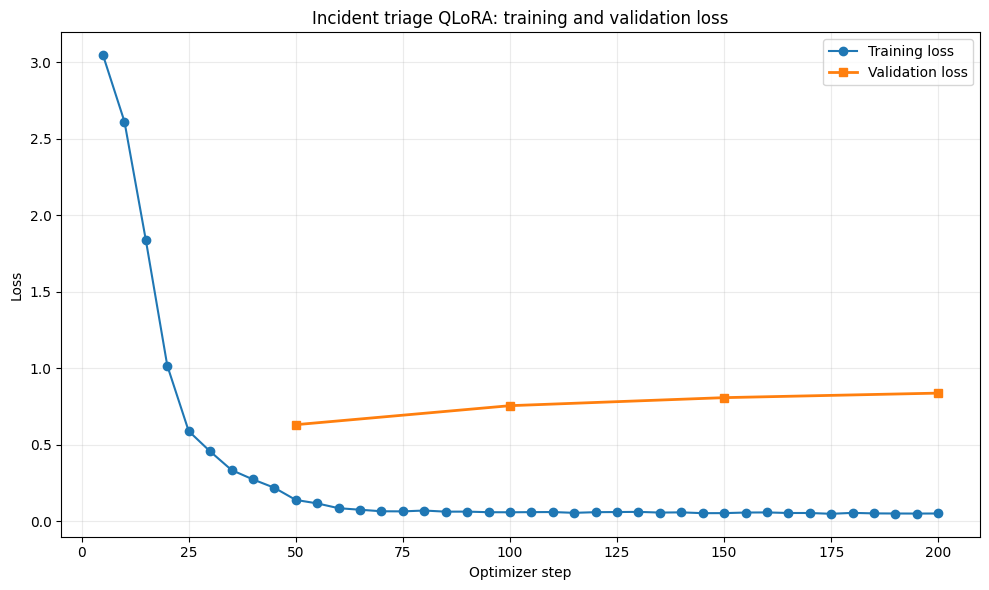

Training log entries: 40
Validation log entries: 4
Training losses: {5: 3.0459802627563475, 10: 2.6123630523681642, 15: 1.8370407104492188, 20: 1.0178154945373534, 25: 0.5899045944213868, 30: 0.45740785598754885, 35: 0.33570754528045654, 40: 0.27430789470672606, 45: 0.21965131759643555, 50: 0.14022471904754638, 55: 0.117678964138031, 60: 0.08625353574752807, 65: 0.07615273594856262, 70: 0.06618185639381409, 75: 0.06544172167778015, 80: 0.0709685206413269, 85: 0.06357487440109252, 90: 0.0638830304145813, 95: 0.06007000207901001, 100: 0.05958431959152222, 105: 0.06053427457809448, 110: 0.061100953817367555, 115: 0.055900925397872926, 120: 0.060237938165664674, 125: 0.06112028956413269, 130: 0.06225492358207703, 135: 0.057673943042755124, 140: 0.05906696319580078, 145: 0.05376489162445068, 150: 0.05401954650878906, 155: 0.05784173011779785, 160: 0.05863347053527832, 165: 0.05494704842567444, 170: 0.054848766326904295, 175: 0.04965026080608368, 180: 0.05565937161445618, 185: 0.052272665500

In [20]:
import csv

import matplotlib.pyplot as plt

log_history = trainer.state.log_history
with (RESULTS_DIR / "trainer-log-history.json").open("w", encoding="utf-8") as handle:
    json.dump(log_history, handle, indent=2)

training_by_step = {
    entry["step"]: entry["loss"]
    for entry in log_history
    if "step" in entry and "loss" in entry
}
validation_by_step = {
    entry["step"]: entry["eval_loss"]
    for entry in log_history
    if "step" in entry and "eval_loss" in entry
}
steps = sorted(set(training_by_step) | set(validation_by_step))

with (RESULTS_DIR / "loss-history.csv").open("w", encoding="utf-8", newline="") as handle:
    writer = csv.writer(handle)
    writer.writerow(["step", "training_loss", "validation_loss"])
    for step in steps:
        writer.writerow([
            step,
            training_by_step.get(step, ""),
            validation_by_step.get(step, ""),
        ])

fig, ax = plt.subplots(figsize=(10, 6))
ax.plot(
    sorted(training_by_step),
    [training_by_step[step] for step in sorted(training_by_step)],
    marker="o",
    linewidth=1.5,
    label="Training loss",
)
ax.plot(
    sorted(validation_by_step),
    [validation_by_step[step] for step in sorted(validation_by_step)],
    marker="s",
    linewidth=2,
    label="Validation loss",
)
ax.set_xlabel("Optimizer step")
ax.set_ylabel("Loss")
ax.set_title("Incident triage QLoRA: training and validation loss")
ax.legend()
ax.grid(True, alpha=0.25)
fig.tight_layout()
fig.savefig(RESULTS_DIR / "loss-diagram.png", dpi=160)
plt.show()

print("Training log entries:", len(training_by_step))
print("Validation log entries:", len(validation_by_step))
print("Training losses:", training_by_step)
print("Validation losses:", validation_by_step)
print("Trainer stats:", trainer_stats)
print("Saved loss history and diagram to:", RESULTS_DIR)


In [22]:
FastLanguageModel.for_inference(model)

print("ALERT:\n", sample["alert"])
print("\nFINE-TUNED OUTPUT:\n", generate_answer(sample["alert"]))
print("\nTARGET:\n", sample["target"])


Both `max_new_tokens` (=180) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


ALERT:
 Token verification began failing after last night's signing-key rotation. Old and new keys are being served inconsistently across authentication nodes. Customer support is monitoring the situation. Incident reference: INC-02061.

FINE-TUNED OUTPUT:
 {"service":"authentication","severity":"sev3","category":"deployment_regression","summary":"Token validations are failing because different parts of the network use distinct key rings","next_action":"inspect_auth_configuration","escalate":false}

TARGET:
 {"service": "authentication", "severity": "sev2", "category": "authentication", "summary": "A signing-key rotation broke token verification", "next_action": "inspect_auth_configuration", "escalate": true}


In [23]:
finetuned_predictions = evaluate_model(eval_records, mode="finetuned")
finetuned_metrics = summarize_predictions(finetuned_predictions)

with (RESULTS_DIR / "finetuned_predictions.json").open("w", encoding="utf-8") as handle:
    json.dump(finetuned_predictions, handle, ensure_ascii=False, indent=2)

with (RESULTS_DIR / "finetuned_metrics.json").open("w", encoding="utf-8") as handle:
    json.dump(finetuned_metrics, handle, indent=2)

comparison = pd.DataFrame({
    "base": pd.Series(base_metrics),
    "finetuned": pd.Series(finetuned_metrics),
})
comparison["difference"] = comparison["finetuned"] - comparison["base"]
comparison


Both `max_new_tokens` (=180) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=180) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


finetuned: 1/40

Both `max_new_tokens` (=180) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


finetuned: 2/40

Both `max_new_tokens` (=180) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


...

Both `max_new_tokens` (=180) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


finetuned: 38/40

Both `max_new_tokens` (=180) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


finetuned: 40/40


,base,finetuned,difference
cases,40.0,40.000,0.000
json_valid_rate,0.0,1.000,1.000
schema_valid_rate,0.0,1.000,1.000
exact_match_rate,0.0,0.000,0.000
service_accuracy,0.0,0.975,0.975
severity_accuracy,0.0,0.425,0.425
category_accuracy,0.0,0.600,0.600
summary_accuracy,0.0,0.000,0.000
next_action_accuracy,0.0,0.700,0.700
escalate_accuracy,0.0,0.600,0.600


In [24]:
rate_metrics = [name for name in base_metrics if name != "cases"]
percentages = comparison.loc[rate_metrics, ["base", "finetuned", "difference"]] * 100
percentages.round(2)


,base,finetuned,difference
json_valid_rate,0.0,100.0,100.0
schema_valid_rate,0.0,100.0,100.0
exact_match_rate,0.0,0.0,0.0
service_accuracy,0.0,97.5,97.5
severity_accuracy,0.0,42.5,42.5
category_accuracy,0.0,60.0,60.0
summary_accuracy,0.0,0.0,0.0
next_action_accuracy,0.0,70.0,70.0
escalate_accuracy,0.0,60.0,60.0
unknown_category_recall,0.0,100.0,100.0


In [25]:
saved_base = json.loads((RESULTS_DIR / "base_metrics.json").read_text())
saved_finetuned = json.loads((RESULTS_DIR / "finetuned_metrics.json").read_text())
print("Metric | Base % | Fine-tuned % | Absolute change (percentage points)")
for name in saved_base:
    if name == "cases":
        continue
    base_value = saved_base[name] * 100
    finetuned_value = saved_finetuned[name] * 100
    print(f"{name} | {base_value:.2f} | {finetuned_value:.2f} | {finetuned_value - base_value:+.2f}")
print("Cases:", saved_finetuned["cases"])
print("Saved fine-tuned prediction rows:", len(json.loads((RESULTS_DIR / "finetuned_predictions.json").read_text())))
print("Fine-tuned metrics file:", RESULTS_DIR / "finetuned_metrics.json")
print("Fine-tuned predictions file:", RESULTS_DIR / "finetuned_predictions.json")


Metric | Base % | Fine-tuned % | Absolute change (percentage points)
json_valid_rate | 0.00 | 100.00 | +100.00
schema_valid_rate | 0.00 | 100.00 | +100.00
exact_match_rate | 0.00 | 0.00 | +0.00
service_accuracy | 0.00 | 97.50 | +97.50
severity_accuracy | 0.00 | 42.50 | +42.50
category_accuracy | 0.00 | 60.00 | +60.00
summary_accuracy | 0.00 | 0.00 | +0.00
next_action_accuracy | 0.00 | 70.00 | +70.00
escalate_accuracy | 0.00 | 60.00 | +60.00
unknown_category_recall | 0.00 | 100.00 | +100.00
Cases: 40
Saved fine-tuned prediction rows: 40
Fine-tuned metrics file: /content/drive/MyDrive/nightthoughts-incident-triage/results/finetuned_metrics.json
Fine-tuned predictions file: /content/drive/MyDrive/nightthoughts-incident-triage/results/finetuned_predictions.json


In [26]:
failures = [p for p in finetuned_predictions if not p["exact_match"]]
print("Fine-tuned failures:", len(failures), "of", len(finetuned_predictions))

for failure in failures[:5]:
    print("\nSCENARIO:", failure["scenario_id"])
    print("ALERT:", failure["alert"])
    print("MODEL OUTPUT:", failure["raw_output"])
    print("TARGET:", json.dumps(failure["target"], ensure_ascii=False))
    print("JSON valid:", failure["json_valid"], "Schema valid:", failure["schema_valid"])


Fine-tuned failures: 40 of 40

SCENARIO: auth_key_rotation
ALERT: Token verification began failing after last night's signing-key rotation. Old and new keys are being served inconsistently across authentication nodes. Customer support is monitoring the situation. Incident reference: INC-02061.
MODEL OUTPUT: {"service":"authentication","severity":"sev3","category":"deployment_regression","summary":"Token validations are failing because different parts of the network use distinct key rings","next_action":"inspect_auth_configuration","escalate":false}
TARGET: {"service": "authentication", "severity": "sev2", "category": "authentication", "summary": "A signing-key rotation broke token verification", "next_action": "inspect_auth_configuration", "escalate": true}
JSON valid: True Schema valid: True

SCENARIO: auth_key_rotation
ALERT: Incident update: Token verification began failing after last night's signing-key rotation. Old and new keys are being served inconsistently across authenticatio

In [27]:
def correct_fields(prediction):
    return [
        field
        for field in TARGET_FIELDS
        if prediction[f"{field}_correct"]
    ]

ranked = sorted(
    finetuned_predictions,
    key=lambda prediction: (len(correct_fields(prediction)), prediction["scenario_id"]),
    reverse=True,
)
print("Best fine-tuned held-out cases by exact field matches:")
for prediction in ranked[:3]:
    fields = correct_fields(prediction)
    print("\nSCENARIO:", prediction["scenario_id"])
    print("CORRECT FIELDS:", fields, f"({len(fields)}/6)")
    print("ALERT:", prediction["alert"])
    print("MODEL OUTPUT:", prediction["raw_output"])
    print("TARGET:", json.dumps(prediction["target"], ensure_ascii=False))
    print("EXACT MATCH:", prediction["exact_match"])

print("\nPer-scenario fine-tuned behavior:")
for scenario_id in sorted(by_scenario):
    rows = [p for p in finetuned_predictions if p["scenario_id"] == scenario_id]
    print(scenario_id, {
        "cases": len(rows),
        "schema_valid": sum(p["schema_valid"] for p in rows),
        "category_correct": sum(p["category_correct"] for p in rows),
        "severity_correct": sum(p["severity_correct"] for p in rows),
        "exact_match": sum(p["exact_match"] for p in rows),
    })


Best fine-tuned held-out cases by exact field matches:

SCENARIO: unknown_worker_saturation
CORRECT FIELDS: ['service', 'severity', 'category', 'next_action', 'escalate'] (5/6)
ALERT: Several workers report high CPU and slower processing. There is no confirmed owning service, recent release, dependency failure, or authentication evidence. Customer support is monitoring the situation. Incident reference: INC-02221.
MODEL OUTPUT: {"service":"unknown","severity":"sev3","category":"unknown","summary":"Workers are reporting slow queries and CPU errors","next_action":"request_more_context","escalate":false}
TARGET: {"service": "unknown", "severity": "sev3", "category": "unknown", "summary": "Generic worker saturation has no isolated root cause", "next_action": "request_more_context", "escalate": false}
EXACT MATCH: False

SCENARIO: unknown_worker_saturation
CORRECT FIELDS: ['service', 'severity', 'category', 'next_action', 'escalate'] (5/6)
ALERT: Several workers report high CPU and slower p

In [28]:
model.save_pretrained(str(ADAPTER_DIR))
tokenizer.save_pretrained(str(ADAPTER_DIR))

print("Adapter saved to:", ADAPTER_DIR)
print("Files:", sorted(path.name for path in ADAPTER_DIR.iterdir()))


Unsloth: Restored added_tokens_decoder metadata in /content/drive/MyDrive/nightthoughts-incident-triage/adapter/tokenizer_config.json.


Adapter saved to: /content/drive/MyDrive/nightthoughts-incident-triage/adapter
Files: ['README.md', 'adapter_config.json', 'adapter_model.safetensors', 'chat_template.jinja', 'tokenizer.json', 'tokenizer_config.json']


In [29]:
from unsloth import FastLanguageModel

ADAPTER_DIR = "/content/drive/MyDrive/nightthoughts-incident-triage/adapter"

model, tokenizer = FastLanguageModel.from_pretrained(
    model_name=ADAPTER_DIR,
    max_seq_length=1024,
    dtype=None,
    load_in_4bit=True,
)

FastLanguageModel.for_inference(model)
print("Adapter reloaded.")


==((====))==  Unsloth 2026.10.10: Fast Qwen2 patching. Transformers: 5.17.0.
   \\   /|    NVIDIA RTX PRO 6000 Blackwell Server Edition. Num GPUs = 1. Max memory: 94.971 GB. Platform: Linux.
O^O/ \_/ \    Torch: 2.11.0+cu130. CUDA: 12.0. CUDA Toolkit: 13.0. Triton: 3.6.0
\        /    Bfloat16 = TRUE. FA [Xformers = None. FA2 = False]
 "-____-"     Free license: http://github.com/unslothai/unsloth
Unsloth: Fast downloading is enabled - ignore downloading bars which are red colored!


Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

Unsloth: compiling each transformer block as one region (Qwen2DecoderLayer).
Adapter reloaded.


In [30]:
def route_incident(alert):
    raw_output = generate_answer(alert)
    parsed, json_valid, schema_valid = validate_prediction(raw_output)

    if not schema_valid:
        return {
            "status": "manual_review",
            "reason": "The model output did not satisfy the incident schema.",
            "raw_output": raw_output,
        }

    if parsed["category"] == "unknown":
        return {
            "status": "request_more_context",
            "report": parsed,
        }

    return {
        "status": "validated_for_human_review",
        "report": parsed,
    }


In [31]:
unknown_alert = next(
    prediction["alert"]
    for prediction in finetuned_predictions
    if prediction["scenario_id"] == "unknown_worker_saturation"
)
unknown_route = route_incident(unknown_alert)

real_generate_answer = generate_answer
try:
    generate_answer = lambda alert: "```json\n{}\n```"
    invalid_route = route_incident("Synthetic schema-rejection test")
finally:
    generate_answer = real_generate_answer

schema_validation_demo = {
    "unknown_category_route": unknown_route,
    "invalid_output_route": invalid_route,
}
assert unknown_route["status"] == "request_more_context"
assert invalid_route["status"] == "manual_review"

with (RESULTS_DIR / "schema-validation-demo.json").open("w", encoding="utf-8") as handle:
    json.dump(schema_validation_demo, handle, ensure_ascii=False, indent=2)
print(json.dumps(schema_validation_demo, ensure_ascii=False, indent=2))
print("Saved schema-validation demonstration to:", RESULTS_DIR / "schema-validation-demo.json")


Both `max_new_tokens` (=180) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


{
  "unknown_category_route": {
    "status": "request_more_context",
    "report": {
      "service": "unknown",
      "severity": "sev3",
      "category": "unknown",
      "summary": "Workers are reporting slow queries and CPU errors",
      "next_action": "request_more_context",
      "escalate": false
    }
  },
  "invalid_output_route": {
    "status": "manual_review",
    "reason": "The model output did not satisfy the incident schema.",
    "raw_output": "```json\n{}\n```"
  }
}
Saved schema-validation demonstration to: /content/drive/MyDrive/nightthoughts-incident-triage/results/schema-validation-demo.json


In [33]:
import hashlib
import importlib.metadata
import platform
import sys
from datetime import datetime, timezone


def package_version(name):
    try:
        return importlib.metadata.version(name)
    except importlib.metadata.PackageNotFoundError:
        return None


def file_sha256(path):
    return hashlib.sha256(path.read_bytes()).hexdigest()

package_names = [
    "unsloth",
    "unsloth-zoo",
    "torch",
    "transformers",
    "trl",
    "peft",
    "datasets",
    "accelerate",
    "bitsandbytes",
    "xformers",
    "pandas",
    "matplotlib",
]
artifact_paths = [
    DATA_DIR / "train.jsonl",
    DATA_DIR / "validation.jsonl",
    DATA_DIR / "test.jsonl",
    RESULTS_DIR / "base_metrics.json",
    RESULTS_DIR / "base_predictions.json",
    RESULTS_DIR / "finetuned_metrics.json",
    RESULTS_DIR / "finetuned_predictions.json",
    RESULTS_DIR / "loss-history.csv",
    RESULTS_DIR / "loss-diagram.png",
]
run_metadata = {
    "recorded_at_utc": datetime.now(timezone.utc).isoformat(),
    "python": sys.version.split()[0],
    "platform": platform.platform(),
    "packages": {name: package_version(name) for name in package_names},
    "hardware": {
        "gpu": torch.cuda.get_device_name(0),
        "vram_bytes": torch.cuda.get_device_properties(0).total_memory,
        "cuda_available": torch.cuda.is_available(),
        "torch_cuda": torch.version.cuda,
        "bf16_supported": torch.cuda.is_bf16_supported(),
    },
    "base_model": BASE_MODEL,
    "max_seq_length": MAX_SEQ_LENGTH,
    "generation": {
        "max_new_tokens": 180,
        "do_sample": False,
    },
    "dataset": {
        "seed": 3407,
        "train_examples": len(train_records),
        "validation_examples": len(validation_records),
        "test_examples": len(test_records),
        "unique_alerts": len({record["alert"] for record in records}),
        "scenario_counts": {split: len(ids) for split, ids in scenario_sets.items()},
        "evaluation_cases": len(eval_records),
        "evaluation_cases_per_test_scenario": EVAL_PER_SCENARIO,
    },
    "qlora": {
        "load_in_4bit": True,
        "rank": 16,
        "alpha": 16,
        "dropout": 0,
        "bias": "none",
        "target_modules": [
            "q_proj", "k_proj", "v_proj", "o_proj",
            "gate_proj", "up_proj", "down_proj",
        ],
    },
    "training": {
        "optimizer_steps": 200,
        "per_device_train_batch_size": 2,
        "per_device_eval_batch_size": 4,
        "gradient_accumulation_steps": 4,
        "effective_train_batch_size": 8,
        "warmup_steps": 10,
        "learning_rate": 0.0002,
        "logging_steps": 5,
        "eval_steps": 50,
        "save_strategy": "no",
        "optimizer": "adamw_8bit",
        "weight_decay": 0.01,
        "lr_scheduler_type": "linear",
        "seed": 3407,
        "trainer_metrics": trainer_stats.metrics,
    },
    "loss_history": log_history,
    "drive_paths": {
        "project": str(PROJECT_DIR),
        "data": str(DATA_DIR),
        "results": str(RESULTS_DIR),
        "adapter": str(ADAPTER_DIR),
    },
    "artifact_sha256": {
        path.name: file_sha256(path)
        for path in artifact_paths
    },
    "adapter_files": {
        path.name: path.stat().st_size
        for path in sorted(Path(ADAPTER_DIR).iterdir())
        if path.is_file()
    },
    "compatibility_notes": [
        "Unsloth reported that xformers was built for torch 2.10.0+cu128 while the runtime used torch 2.11.0+cu130; PyTorch attention was used instead.",
        "Generation warned that max_new_tokens=180 took precedence over max_length=32768; generation was not truncated, so 180 was kept for both evaluations.",
    ],
}
with (RESULTS_DIR / "run-metadata.json").open("w", encoding="utf-8") as handle:
    json.dump(run_metadata, handle, ensure_ascii=False, indent=2)
print(json.dumps({
    "packages": run_metadata["packages"],
    "hardware": run_metadata["hardware"],
    "training": run_metadata["training"],
    "loss_history": log_history,
    "drive_paths": run_metadata["drive_paths"],
}, indent=2))
print("Saved run metadata to:", RESULTS_DIR / "run-metadata.json")


{
  "packages": {
    "unsloth": "2026.10.10",
    "unsloth-zoo": "2026.10.10",
    "torch": "2.11.0+cu130",
    "transformers": "5.17.0",
    "trl": "1.15.0",
    "peft": "0.21.2",
    "datasets": "4.8.5",
    "accelerate": "1.15.0",
    "bitsandbytes": "0.50.2",
    "xformers": "0.0.35",
    "pandas": "2.2.3",
    "matplotlib": "3.10.0"
  },
  "hardware": {
    "gpu": "NVIDIA RTX PRO 6000 Blackwell Server Edition",
    "vram_bytes": 101974081536,
    "cuda_available": true,
    "torch_cuda": "13.0",
    "bf16_supported": true
  },
  "training": {
    "optimizer_steps": 200,
    "per_device_train_batch_size": 2,
    "per_device_eval_batch_size": 4,
    "gradient_accumulation_steps": 4,
    "effective_train_batch_size": 8,
    "warmup_steps": 10,
    "learning_rate": 0.0002,
    "logging_steps": 5,
    "eval_steps": 50,
    "save_strategy": "no",
    "optimizer": "adamw_8bit",
    "weight_decay": 0.01,
    "lr_scheduler_type": "linear",
    "seed": 3407,
    "trainer_metrics": {
      

In [34]:
import zipfile

from google.colab import files

archive_path = Path("/content/incident-triage-artifacts.zip")
with zipfile.ZipFile(archive_path, "w", compression=zipfile.ZIP_DEFLATED) as archive:
    for directory in [DATA_DIR, RESULTS_DIR]:
        for path in sorted(directory.iterdir()):
            if path.is_file():
                archive.write(path, arcname=str(path.relative_to(PROJECT_DIR)))
print("Export archive:", archive_path)
print("Size (bytes):", archive_path.stat().st_size)
print("Contents: data and results only; adapter weights are not included.")
files.download(str(archive_path))


Export archive: /content/incident-triage-artifacts.zip
Size (bytes): 97745
Contents: data and results only; adapter weights are not included.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>